In [113]:
import pandas as pd 
import numpy as np 
import re
from tableone import TableOne

pd.set_option('display.max_rows', 100)  # Show up to 100 rows
pd.set_option('display.max_columns', None)

In [114]:
path = '/Users/herbert.kapesa/Library/CloudStorage/OneDrive-CentreforInfectiousDiseaseResearchinZambia/RMNCH/PPD 2/Data extract/Latest Extract/KMCPPD2024_DATA_LABELS_2026-08-27_2009.csv'
df = pd.read_csv(path)

/var/folders/r2/83tq991d3ng89thh8jc6hk51090g_x/T/ipykernel_89126/1383372992.py:2: DtypeWarning: Columns (8,117,130,131,132,133,135,137,169,180,181,182,189,190,191,192,194,199,200,203,204,206,209,210,212,214,216,218,220,224,225,239,243,245,279,280,284,285,289,290,291,295,319,320,347,349,350,351,353,355,356,357,372,376,378,412,416,417,418,422,423,424,427,429,430,453,456,457,484,486,487,488,489,492,493,494,498,499,501,502,503,504,505,506,507,508,509,510,512,514,515,516,517,518,519,520,521,522,523,524,525,526,527,528,529,530,533,534,535,536,537,538,539,540,541,542,543,545,547,548,549,552,553,554,555,557,558,559,560,561,562,563,564,565,566,567,568,569,578,579,580,581,582,583,584,585,586,587,588,593,594,595,596,602,603,605,606,607,609,611,613,614,615,616,617,618,619,620,621,622,623,624,625,626,627,628,629,630,631,632,633,634,635,636,639,640,641,642,643,644,645,646,647,648,649,651,653,654,655,656,658,659,660,661,663,664,665,666,668,669,670,671,672,673,674,675,676,677,679,681,683,686,687,688,6

In [115]:
df.columns

Index(['participant_id', 'redcap_event_name', 'redcap_repeat_instrument',
       'redcap_repeat_instance', 'notes', 'participant_chart_notes_complete',
       'vi_m_schedule', 'vi_m_motherdate', 'vi_f_fatherdate',
       'vi_f_fatherdate_na',
       ...
       'ci_f_name', 'ci_f_aka', 'ci_f_phone1', 'ci_f_phone2', 'ci_f_name_sc',
       'ci_f_phone_sc1', 'ci_f_phone_sc2', 'ci_f_adress', 'ci_f_map',
       'contact_information_father_complete'],
      dtype='object', length=1041)

In [116]:
df["participant_id"]

0       PPD-M-001
1       PPD-M-001
2       PPD-M-001
3       PPD-M-001
4       PPD-M-001
          ...    
7586    PPD-M-612
7587    PPD-M-612
7588    PPD-M-612
7589    PPD-M-612
7590    PPD-M-612
Name: participant_id, Length: 7591, dtype: object

In [117]:
## Combine participant crfs into one record

def _combine_series(s):
    vals = s.dropna().astype(str).unique()
    if vals.size == 0:
        return np.nan
    if vals.size == 1:
        v = vals[0]
        if pd.api.types.is_numeric_dtype(s):
            try:
                return pd.to_numeric(v)
            except:
                return v
        if pd.api.types.is_bool_dtype(s):
            return v.lower() in ("true", "1", "yes")
        return v
    return " | ".join(vals)

dedup_df = df.groupby("participant_id", sort=False, as_index=False).agg(_combine_series)
print(f"rows before: {len(df)}, rows after: {len(dedup_df)}")
df = dedup_df.copy()

rows before: 7591, rows after: 612


/var/folders/r2/83tq991d3ng89thh8jc6hk51090g_x/T/ipykernel_89126/2991340239.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dedup_df = df.groupby("participant_id", sort=False, as_index=False).agg(_combine_series)


In [118]:
df[['participant_id',"en_m_dob"]].loc[df['en_m_dob'].isna()]

,participant_id,en_m_dob
564,PPD-M-565,NaN


In [119]:
# Convert date strings to datetime
df["en_date"] = pd.to_datetime(df["en_date"], errors="coerce")
df["en_m_dob"] = pd.to_datetime(df["en_m_dob"], errors="coerce")

# Calculate age at enrollment in completed years (no decimal places)
df["mothers_age"] = (
    np.floor((df["en_date"] - df["en_m_dob"]).dt.days / 365.25)
    .astype("Int64")
)
df['mothers_age_group'] = pd.cut(df['mothers_age'], 
                                  bins=[14, 19, 24, 29, 34, 39, 100],
                                  labels=['15-19 years', '20-24 years', '25-29 years', 
                                          '30-34 years', '35-39 years', '40+ years'])

/var/folders/r2/83tq991d3ng89thh8jc6hk51090g_x/T/ipykernel_89126/3991350160.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["en_date"] = pd.to_datetime(df["en_date"], errors="coerce")
/var/folders/r2/83tq991d3ng89thh8jc6hk51090g_x/T/ipykernel_89126/3991350160.py:3: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["en_m_dob"] = pd.to_datetime(df["en_m_dob"], errors="coerce")


In [120]:
# work on parity and gravida
df["en_para"] = pd.to_numeric(df["en_para"], errors="coerce")
df['mothers_par_group'] = pd.cut(df['en_para'], 
                                  bins=[-1,0,1,2, 100],
                                  labels=['0','1', '2', '3+'])

# Work on gravida
df["en_gra"] = pd.to_numeric(df["en_gra"], errors="coerce")
df['mothers_grav_group'] = pd.cut(df['en_gra'], 
                                  bins=[-1,0,1,2, 100],
                                  labels=['0','1', '2', '3+'])          


# Sexual debut age categorization
df["en_m_asxd"] = pd.to_numeric(df["en_m_asxd"], errors="coerce")
df['mothers_sex_debut_group'] = pd.cut(df['en_m_asxd'],
                                       bins=[-1, 14, 18, 100],
                                       labels=['<15 years', '15-18 years', ">18 years"])
# Number of ANC visits categorization
df["en_m_anc"] = pd.to_numeric(df["en_m_anc"], errors="coerce")
df['mothers_anc_group'] = pd.cut(df['en_m_anc'],
                                  bins=[-1, 0,1,2,3, 4, 100],
                                  labels=['0','1','2','3','4', '5+'])
# EPDS score categorization
df["fp_m_scr_epds_sco"] = pd.to_numeric(df["fp_m_scr_epds_sco"], errors="coerce")
df['mothers_epds_group_2weeks'] = pd.cut(df['fp_m_scr_epds_sco'],
                                  bins=[-1,10, 100],
                                  labels=[ 'Negative', 'Positive'])

# EPDS score categorization 6-8 weeks
df["fp1_m_scr_epds_sco"] = pd.to_numeric(df["fp1_m_scr_epds_sco"], errors="coerce")
df['mothers_epds_group_6-8weeks'] = pd.cut(df['fp1_m_scr_epds_sco'],
                                  bins=[-1,10, 100],
                                  labels=[ 'Negative', 'Positive'])     
df[['mothers_epds_group_6-8weeks','fp1_m_scr_epds_sco']]


,mothers_epds_group_6-8weeks,fp1_m_scr_epds_sco
0,Negative,6.0
1,Negative,8.0
2,Negative,6.0
3,Negative,8.0
4,Negative,8.0
...,...,...
607,Negative,0.0
608,Negative,0.0
609,Negative,7.0
610,Negative,9.0


In [121]:
df.shape

(612, 1049)

In [122]:
## raw data copy for MSSRP analysis
df_mssrp = df

In [123]:
df_mssrp

participant_id                                  redcap_event_name  \
0        PPD-M-001  Screening and Eligibility (Arm 1: Control) | E...   
1        PPD-M-002  Screening and Eligibility (Arm 2: Intervention...   
2        PPD-M-003  Screening and Eligibility (Arm 1: Control) | E...   
3        PPD-M-004  Screening and Eligibility (Arm 1: Control) | E...   
4        PPD-M-005  Screening and Eligibility (Arm 2: Intervention...   
..             ...                                                ...   
607      PPD-M-608  Screening and Eligibility (Arm 2: Intervention...   
608      PPD-M-609  Screening and Eligibility (Arm 2: Intervention...   
609      PPD-M-610  Screening and Eligibility (Arm 1: Control) | E...   
610      PPD-M-611  Screening and Eligibility (Arm 2: Intervention...   
611      PPD-M-612  Screening and Eligibility (Arm 2: Intervention...   

                              redcap_repeat_instrument  \
0    Visit Schedule | Hospital Admission And Discha...   
1    Visit Schedule | Hospital Admission And Discha...   
2    Visit Schedule | Hospital Admission And Discha...   
3    Visit Schedule | Hospital Admission And Discha...   
4         Hospital Admission And Discharge Info Mother   
..                                                 ...   
607  Visit Schedule | Hospital Admission And Discha...   
608  Visit Schedule | Hospital Admission And Discha...   
609  Visit Schedule | Hospital Admission And Discha...   
610  Visit Schedule | Hospital Admission And Discha...   
611  Visit Schedule | Hospital Admission And Discha...   

          redcap_repeat_instance  \
0                1.0 | 2.0 | 3.0   
1    1.0 | 2.0 | 3.0 | 4.0 | 5.0   
2                      1.0 | 2.0   
3          1.0 | 2.0 | 3.0 | 4.0   
4                      1.0 | 2.0   
..                           ...   
607  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
608  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
609  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
610  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
611  1.0 | 2.0 | 3.0 | 4.0 | 5.0   

                                                 notes  \
0      THE BABY IS MIXED FEEDING ON DEMAND. 23/01/2026   
1                                                  NaN   
2        THE BABY WAS MIXED FED ON DEMAND. 09/01/2026.   
3    PPD-F-004PARTICIPANT REFERRED FOR FURTHER EVAL...   
4                                                  NaN   
..                                                 ...   
607  THE BABY HAS BEEN BREASTFEEDING EXCLUSIVELY. 0...   
608                                                NaN   
609                                                NaN   
610                                                NaN   
611  THE TWO WEEKS SCREENING WAS DONE OVER THE PHON...   

    participant_chart_notes_complete  \
0                         Unverified   
1                         Incomplete   
2                         Unverified   
3                         Unverified   
4                         Incomplete   
..                               ...   
607                       Unverified   
608                       Incomplete   
609                       Incomplete   
610                       Incomplete   
611                       Unverified   

                                         vi_m_schedule  \
0    Follow up visit  1: 2 weeks | Follow up visit ...   
1    Follow up visit  1: 2 weeks | Follow up visit ...   
2    Follow up visit  1: 2 weeks | Follow up visit ...   
3    Follow up visit  1: 2 weeks | Follow up visit ...   
4                                                  NaN   
..                                                 ...   
607  Follow up visit  1: 2 weeks | Follow up visit ...   
608  Follow up visit  1: 2 weeks | Follow up visit ...   
609  Follow up visit  1: 2 weeks | Follow up visit ...   
610  Follow up visit  1: 2 weeks | Follow up visit ...   
611  Follow up visit  1: 2 weeks | Follow up visit ...   

                                       vi_m_motherdate vi_f_fatherdate  \
0                              28/11/2024 | 07/0

In [124]:
df[['participant_id',"mothers_age_group","mothers_age","en_m_dob"]].loc[df['mothers_age_group']=="15-19 years"]

,participant_id,mothers_age_group,mothers_age,en_m_dob
1,PPD-M-002,15-19 years,18,2005-12-09
9,PPD-M-010,15-19 years,18,2006-05-21
12,PPD-M-013,15-19 years,19,2005-05-23
42,PPD-M-042,15-19 years,19,2006-01-01
65,PPD-M-065,15-19 years,18,2007-02-01
89,PPD-M-089,15-19 years,19,2005-04-14
90,PPD-M-090,15-19 years,19,2005-08-15
91,PPD-M-091,15-19 years,19,2005-11-09
94,PPD-M-094,15-19 years,19,2005-11-22
106,PPD-M-106,15-19 years,18,2007-02-23


In [125]:
df["en_m_mstat"].value_counts()

en_m_mstat
Married              469
In a relationship    119
Single                11
Separated             10
Widowed                1
Divorced               1
Name: count, dtype: int64

In [126]:
columns = [ "mothers_age_group",
"mothers_par_group",
"mothers_grav_group",
"en_misc",
"en_mod",
"en_m_hgt",
"en_m_wgt",
"mothers_sex_debut_group",
"en_m_mstat",
"en_m_hiv",
"en_m_sku",
"en_m_inc",
"en_m_mlev",
"mothers_anc_group",
"en_m_smk",
"en_m_drg",
"en_m_alc",
"mothers_epds_group_2weeks",
'mothers_epds_group_6-8weeks'
]
categorical = ['mothers_age_group',
"mothers_par_group",
"mothers_grav_group",
"en_misc",
"en_mod",
"mothers_sex_debut_group",
"en_m_mstat",
"en_m_hiv",
"en_m_sku",
"en_m_inc",
"en_m_mlev",
"mothers_anc_group",
"en_m_smk",
"en_m_drg",
"en_m_alc",
"mothers_epds_group_2weeks",
'mothers_epds_group_6-8weeks'
]

continuous = ["en_m_hgt","en_m_wgt"]
min_max = ["en_m_hgt","en_m_wgt"]
nonnormal = ["mothers_par_group","mothers_grav_group"]



lables = {
 "mothers_age_group": "Mother's Age Group",
"mothers_par_group": "Mother's Parity Group",
"mothers_grav_group": "Mother's Gravida Group",
"en_misc": "Miscarriages",
"en_mod": "Mode of Delivery",
"en_m_hgt": "Mother's Height",
"en_m_wgt": "Mother's Weight",
"mothers_sex_debut_group": "Mother's Sexual Debut Age Group",
"en_m_mstat": "Mother's Marital Status",
"en_m_hiv": "Mother's HIV Status",
"en_m_sku": "Mother's Education Status",
"en_m_inc": "Mother's Source of Income ",
"en_m_mlev": "Maternal leave",
"mothers_anc_group": "Mother's ANC Visits",
"en_m_smk": "Mother's Smoking Status",
"en_m_drg": "Mother's Drug Use Status",
"en_m_alc": "Mother's Alcohol Use Status",
"mothers_epds_group_2weeks": "Mother's EPDS Score (2 weeks)",
"mothers_epds_group_6-8weeks": "Mother's EPDS Score (6-8 weeks)"
}   

groupby = 'en_rand'

In [127]:
mytable = TableOne(df, columns, categorical, continuous, groupby,min_max=min_max,rename=lables,label_suffix=True, normal_test=True, tukey_test=True, pval=True)

/opt/anaconda3/lib/python3.12/site-packages/tableone/formatting.py:184: UserWarning: Order value not found: "mothers_par_group: ['0']"
  warnings.warn(f'Order value not found: "{k}: {rm_var}"')
/opt/anaconda3/lib/python3.12/site-packages/tableone/formatting.py:184: UserWarning: Order value not found: "mothers_grav_group: ['0']"
  warnings.warn(f'Order value not found: "{k}: {rm_var}"')


In [128]:


mytable

Grouped by en_rand                                                                                                                                       
                                                                                        Missing              Overall Control (NICU → KMC ward for < 48 hours → home) Intervention (Immediate admission to the KMC Ward → home) P-Value
n                                                                                                                612                                             306                                                       306        
Mother's Age Group, n (%)              15-19 years                                                         84 (13.7)                                       45 (14.7)                                                 39 (12.7)   0.279
                                       20-24 years                                                        161 (26.3)                                       79 (25.8)                                                 82 (26.8)        
                                       25-29 years                                                        160 (26.1)                                       84 (27.5)                                                 76 (24.8)        
                                       30-34 years                                                        124 (20.3)                                       66 (21.6)                                                 58 (19.0)        
                                       35-39 years                                                          58 (9.5)                                        21 (6.9)                                                 37 (12.1)        
                                       40+ years                                                            24 (3.9)                                        10 (3.3)                                                  14 (4.6)        
                                       None                                                                  1 (0.2)                                         1 (0.3)                                                   0 (0.0)        
Mother's Parity Group, n (%)           1                                                                  192 (31.4)                                      100 (32.7)                                                 92 (30.1)   0.201
                                       2                                                                  140 (22.9)                                       77 (25.2)                                                 63 (20.6)        
                                       3+                                                                 279 (45.6)                                      128 (41.8)                                                151 (49.3)        
                                       None                                                                  1 (0.2)                                         1 (0.3)                                                   0 (0.0)        
Mother's Gravida Group, n (%)          1                                                                  175 (28.6)                                       91 (29.7)                                                 84 (27.5)   0.172
                                       2                                                                  150 (24.5)                                       83 (27.1)                                                 67 (21.9)        
                                       3+                                                                 286 (46.7)                                      131 (42.8)                                                155 (50.7)        
                                       None                                                                  1 (0.2)                                  

In [129]:
df['mothers_epds_group_2weeks'].value_counts()

mothers_epds_group_2weeks
Negative    500
Positive     84
None         28
Name: count, dtype: int64

In [130]:
df = df.loc[df['mothers_epds_group_2weeks'] != 'None']

In [131]:
epds_table = TableOne(df, columns, categorical, continuous, groupby = "mothers_epds_group_2weeks",min_max=min_max,rename=lables,label_suffix=True, normal_test=True, tukey_test=True, pval=True)

/opt/anaconda3/lib/python3.12/site-packages/tableone/tableone.py:325: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[self._categorical] = handle_categorical_nulls(data[self._categorical], self._categorical)


In [132]:
epds_table

Grouped by Mother's EPDS Score (2 weeks)                                                                       
                                                                                                             Missing              Overall             Negative             Positive P-Value
n                                                                                                                                     584                  500                   84        
Mother's Age Group, n (%)              15-19 years                                                                              79 (13.5)            69 (13.8)            10 (11.9)   0.526
                                       20-24 years                                                                             153 (26.2)           135 (27.0)            18 (21.4)        
                                       25-29 years                                                                             154 (26.4)           128 (25.6)            26 (31.0)        
                                       30-34 years                                                                             119 (20.4)           101 (20.2)            18 (21.4)        
                                       35-39 years                                                                               55 (9.4)             49 (9.8)              6 (7.1)        
                                       40+ years                                                                                 23 (3.9)             17 (3.4)              6 (7.1)        
                                       None                                                                                       1 (0.2)              1 (0.2)              0 (0.0)        
Mother's Parity Group, n (%)           1                                                                                       187 (32.0)           165 (33.0)            22 (26.2)   0.073
                                       2                                                                                       131 (22.4)           118 (23.6)            13 (15.5)        
                                       3+                                                                                      265 (45.4)           216 (43.2)            49 (58.3)        
                                       None                                                                                       1 (0.2)              1 (0.2)              0 (0.0)        
Mother's Gravida Group, n (%)          1                                                                                       168 (28.8)           148 (29.6)            20 (23.8)   0.066
                                       2                                                                                       144 (24.7)           130 (26.0)            14 (16.7)        
                                       3+                                                                                      271 (46.4)           221 (44.2)            50 (59.5)        
                                       None                                                                                       1 (0.2)              1 (0.2)              0 (0.0)        
Miscarriages, n (%)                    0.0                                                                                     466 (79.8)           409 (81.8)            57 (67.9)   0.048
                                       1.0                                                                                      86 (14.7)            64 (12.8)            22 (26.2)        
                                       2.0                                                                                       20 (3.4)             16 (3.2)              4 (4.8)        
                                       3.0                                                                                      

In [133]:
df['mothers_epds_group_2weeks'].value_counts()

mothers_epds_group_2weeks
Negative    500
Positive     84
Name: count, dtype: int64

In [134]:
# Create an Excel writer object
with pd.ExcelWriter('/Users/herbert.kapesa/Library/CloudStorage/OneDrive-CentreforInfectiousDiseaseResearchinZambia/RMNCH/PPD 2/output_tables/ppd_tables.xlsx', engine='openpyxl') as writer:
    # Write the first table to the first sheet
    mytable.tableone.to_excel(writer, sheet_name='Overall Table')
    
    # Write the second table to the second sheet
    epds_table.tableone.to_excel(writer, sheet_name='EPDS Table')

# logistic GEE analysis

In [135]:
# Drop missing epds scores at 6-8 weeks
df = df.dropna(subset=['fp1_m_scr_epds_sco'])


df['2weeks'] = df['mothers_epds_group_2weeks']
df['6_8weeks'] = df['mothers_epds_group_6-8weeks']

# Copy database for logistic regression analysis
df_logit = df[['participant_id','2weeks','6_8weeks','en_rand']].copy()

# data variable transformation for logistic regression
# Randomisation group
df_logit['en_rand'] = df_logit['en_rand'].map({'Control (NICU → KMC ward for < 48 hours → home)': 'Control', 'Intervention (Immediate admission to the KMC Ward → home)': 'Intervention'})
df_logit['en_rand_num'] = df_logit['en_rand'].map({ 'Control' : 0, 'Intervention' : 1 })
# Timepoint



In [136]:
# tranform dataframe from wide to long format for logistic regression analysis

df_logit_long = pd.melt(
    df_logit, 
    id_vars=['participant_id','en_rand'], 
    value_vars=['2weeks', '6_8weeks'], 
    var_name='timepoint', value_name='epds_result')

df_logit_long.sort_values(by=['participant_id'], inplace=True)

# Change the 'timepoint' and 'epds_result' columns to numeric values for logistic regression
df_logit_long['timepoint_num'] = df_logit_long['timepoint'].map({'2weeks': 0, '6_8weeks': 1})
df_logit_long['epds_result_num'] = df_logit_long['epds_result'].map({'Negative': 0, 'Positive': 1})


In [137]:
# check for duplicate ids
duplicates = df_logit_long[
    df_logit_long.duplicated(
        subset=["participant_id", "timepoint"],
        keep=False
    )
]

print(duplicates)

Empty DataFrame
Columns: [participant_id, en_rand, timepoint, epds_result, timepoint_num, epds_result_num]
Index: []


In [138]:
#checking for available epds data
participant_counts = (
    df_logit_long
    .groupby("participant_id")["epds_result"]
    .nunique()
)

print(participant_counts.value_counts())

epds_result
1    453
2     88
Name: count, dtype: int64


In [139]:
df_logit_long['epds_result'].value_counts(dropna=False)

epds_result
Negative    968
Positive    114
Name: count, dtype: int64

In [140]:
summary = (
    df_logit_long
    .groupby(["en_rand", "timepoint"])
    .agg(
        n=("epds_result_num", "size"),
        positive=("epds_result_num", "sum"),
        positivity=("epds_result_num", "mean")
    )
    .reset_index()
)

summary["positivity_percent"] = summary["positivity"] * 100

print(summary)

        en_rand timepoint    n  positive  positivity  positivity_percent
0       Control    2weeks  269        49    0.182156           18.215613
1       Control  6_8weeks  269        22    0.081784            8.178439
2  Intervention    2weeks  272        32    0.117647           11.764706
3  Intervention  6_8weeks  272        11    0.040441            4.044118


In [141]:
positivity_table = df_logit_long.pivot_table(
    index="en_rand",
    columns="timepoint",
    values="epds_result_num",
    aggfunc="mean"
) * 100

print(positivity_table)

timepoint        2weeks  6_8weeks
en_rand                          
Control       18.215613  8.178439
Intervention  11.764706  4.044118


In [142]:
positivity_table

timepoint,2weeks,6_8weeks
en_rand,,
Control,18.215613,8.178439
Intervention,11.764706,4.044118


In [143]:
positivity_table["change"] = (
    positivity_table['2weeks']
    - positivity_table['6_8weeks']
)

print(positivity_table)

timepoint        2weeks  6_8weeks     change
en_rand                                     
Control       18.215613  8.178439  10.037175
Intervention  11.764706  4.044118   7.720588


# Logistic GEE

In [144]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [145]:
df_logit_long["group"] = pd.Categorical(
    df_logit_long["en_rand"],
    categories=["Control", "Intervention"]
)

df_logit_long["timepoint"] = pd.Categorical(
    df_logit_long["timepoint"],
    categories=["2weeks", "6_8weeks"]
)

In [146]:
model = smf.gee(
    formula="epds_result_num ~ group * timepoint",
    groups="participant_id",
    data=df_logit_long,
    family=sm.families.Binomial(),
    cov_struct=sm.cov_struct.Exchangeable()
)

result = model.fit()

print(result.summary())

                               GEE Regression Results                              
Dep. Variable:             epds_result_num   No. Observations:                 1082
Model:                                 GEE   No. clusters:                      541
Method:                        Generalized   Min. cluster size:                   2
                      Estimating Equations   Max. cluster size:                   2
Family:                           Binomial   Mean cluster size:                 2.0
Dependence structure:         Exchangeable   Num. iterations:                     2
Date:                     Thu, 27 Aug 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         22:10:20
                                                  coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------
Intercept           

In [147]:
params = result.params
conf = result.conf_int()

or_table = pd.DataFrame({
    "OR": np.exp(params),
    "CI_lower": np.exp(conf[0]),
    "CI_upper": np.exp(conf[1]),
    "p_value": result.pvalues
})

print(or_table)

                                                   OR  CI_lower  CI_upper  \
Intercept                                    0.222727  0.163422  0.303554   
group[T.Intervention]                        0.598639  0.369847  0.968966   
timepoint[T.6_8weeks]                        0.399901  0.245356  0.651792   
group[T.Intervention]:timepoint[T.6_8weeks]  0.790426  0.348878  1.790807   

                                                  p_value  
Intercept                                    1.960775e-21  
group[T.Intervention]                        3.677341e-02  
timepoint[T.6_8weeks]                        2.357316e-04  
group[T.Intervention]:timepoint[T.6_8weeks]  5.730172e-01  


In [148]:
# Get predicted positivity probabilities

prediction_df = pd.DataFrame({
    "group": [
        "Control",
        "Control",
        "Intervention",
        "Intervention"
    ],
    "timepoint": [
        "2weeks",
        "6_8weeks",
        "2weeks",
        "6_8weeks"
    ]
})

prediction_df["predicted_probability"] = (
    result.predict(prediction_df)
)

prediction_df["predicted_percent"] = (
    prediction_df["predicted_probability"] * 100
)

print(prediction_df)


          group timepoint  predicted_probability  predicted_percent
0       Control    2weeks               0.182156          18.215613
1       Control  6_8weeks               0.081784           8.178439
2  Intervention    2weeks               0.117647          11.764706
3  Intervention  6_8weeks               0.040441           4.044118


/var/folders/r2/83tq991d3ng89thh8jc6hk51090g_x/T/ipykernel_89126/1307884768.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for group_name, temp in plot_df.groupby("group"):


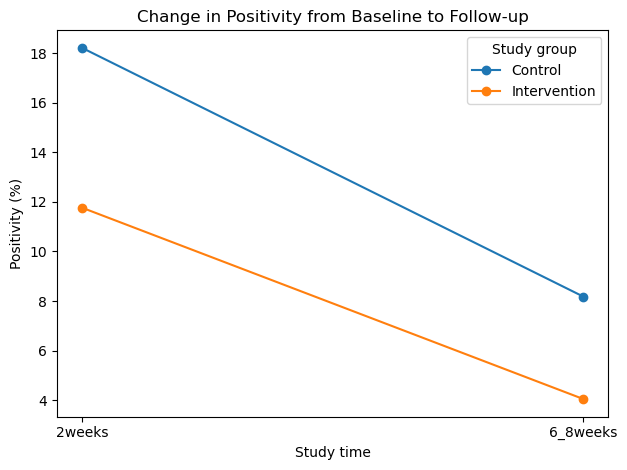

In [149]:
import matplotlib.pyplot as plt

plot_df = (
    df_logit_long
    .groupby(["group", "timepoint"], observed=False)["epds_result_num"]
    .mean()
    .reset_index()
)

plot_df["positivity_percent"] = (
    plot_df["epds_result_num"] * 100
)

for group_name, temp in plot_df.groupby("group"):
    plt.plot(
        temp["timepoint"],
        temp["positivity_percent"],
        marker="o",
        label=group_name.capitalize()
    )

plt.xlabel("Study time")
plt.ylabel("Positivity (%)")
plt.title("Change in Positivity from Baseline to Follow-up")
plt.legend(title="Study group")
plt.tight_layout()
plt.show()

#### Interpretation of GEE Regression Results

A generalized estimating equation (GEE) model with a binomial distribution and exchangeable correlation structure was used to assess changes in the odds of a positive EPDS result between **2 weeks** and **6–8 weeks postpartum**, and to determine whether this change differed between the **control** and **intervention** groups.

The analysis included **1,131 observations from 590 participants**, with a mean of 1.9 observations per participant.

#### Main Findings

At **2 weeks postpartum**, participants in the intervention group had significantly lower odds of a positive EPDS result compared with participants in the control group (**OR = 0.61, 95% CI: 0.38–0.98, p = 0.041**). This corresponds to approximately **39% lower odds of EPDS positivity** in the intervention group at the baseline timepoint.

Among participants in the **control group**, the odds of a positive EPDS result were significantly lower at **6–8 weeks** compared with **2 weeks postpartum** (**OR = 0.41, 95% CI: 0.25–0.68, p < 0.001**). This corresponds to approximately **59% lower odds of positivity** at follow-up.

However, the **group × time interaction** was not statistically significant (**OR = 0.78, 95% CI: 0.34–1.77, p = 0.547**). This indicates that there was **no statistically significant evidence that the change in EPDS positivity from 2 weeks to 6–8 weeks differed between the intervention and control groups**.

#### GEE Model Results

| Model term | Coefficient (β) | Adjusted OR | 95% CI for OR | p-value | Interpretation |
|---|---:|---:|---:|---:|---|
| Intercept | -1.563 | 0.21 | 0.15–0.28 | <0.001 | Odds of positivity in the control group at 2 weeks |
| Intervention vs Control at 2 weeks | -0.491 | 0.61 | 0.38–0.98 | **0.041** | Intervention group had lower baseline odds of positivity |
| 6–8 weeks vs 2 weeks in Control | -0.882 | 0.41 | 0.25–0.68 | **<0.001** | Positivity odds decreased significantly over time in the control group |
| Intervention × 6–8 weeks | -0.253 | 0.78 | 0.34–1.77 | 0.547 | No statistically significant difference in change over time between groups |

**Reference categories:** Control group and 2-week timepoint.

#### Interpretation of the Intervention Effect

The most important estimate for assessing the effect of the intervention is the **group × time interaction**:

\[
OR_{\text{interaction}} = 0.78
\]

Although the point estimate is below 1, suggesting that the intervention group may have experienced a somewhat greater reduction in positivity over time than the control group, the 95% confidence interval is wide and includes 1:

\[
95\%\,CI = 0.34 - 1.77
\]

The interaction was also not statistically significant:

\[
p = 0.547
\]

Therefore, the study does **not provide evidence that the intervention produced a significantly greater reduction in EPDS positivity between 2 weeks and 6–8 weeks compared with the control group**.

An important feature of these results is that the intervention and control groups were already significantly different at 2 weeks. The intervention group had lower odds of positivity at the initial measurement. This means that simply comparing the two groups at follow-up could be misleading. The interaction term is therefore the appropriate estimate for evaluating whether the **change over time differed between groups**.

#### Suggested Scientific Reporting

> A binomial generalized estimating equation model with an exchangeable working correlation structure was used to examine differences in EPDS positivity between the intervention and control groups over time. The analysis included 1,131 observations from 590 participants. At 2 weeks postpartum, participants in the intervention group had significantly lower odds of EPDS positivity compared with those in the control group (OR = 0.61, 95% CI: 0.38–0.98; p = 0.041). In the control group, the odds of EPDS positivity decreased significantly between 2 weeks and 6–8 weeks postpartum (OR = 0.41, 95% CI: 0.25–0.68; p < 0.001). However, there was no significant group-by-time interaction (OR = 0.78, 95% CI: 0.34–1.77; p = 0.547), indicating that the reduction in EPDS positivity over time did not differ significantly between the intervention and control groups.

#### Overall Conclusion

The results suggest that EPDS positivity decreased over time, particularly within the control group. Although the intervention group had lower odds of positivity at 2 weeks, there was **no statistically significant evidence that the intervention group experienced a greater reduction in positivity over time compared with the control group**.

The absence of a statistically significant interaction should not be interpreted as proof that the intervention had no effect. Rather, the findings indicate that the available data did not provide sufficient evidence of a differential change between the two study groups during the observed follow-up period.

# MSSRP Abstract Due 28-08-2026

In [150]:
df_mssrp

participant_id                                  redcap_event_name  \
0        PPD-M-001  Screening and Eligibility (Arm 1: Control) | E...   
1        PPD-M-002  Screening and Eligibility (Arm 2: Intervention...   
2        PPD-M-003  Screening and Eligibility (Arm 1: Control) | E...   
3        PPD-M-004  Screening and Eligibility (Arm 1: Control) | E...   
4        PPD-M-005  Screening and Eligibility (Arm 2: Intervention...   
..             ...                                                ...   
607      PPD-M-608  Screening and Eligibility (Arm 2: Intervention...   
608      PPD-M-609  Screening and Eligibility (Arm 2: Intervention...   
609      PPD-M-610  Screening and Eligibility (Arm 1: Control) | E...   
610      PPD-M-611  Screening and Eligibility (Arm 2: Intervention...   
611      PPD-M-612  Screening and Eligibility (Arm 2: Intervention...   

                              redcap_repeat_instrument  \
0    Visit Schedule | Hospital Admission And Discha...   
1    Visit Schedule | Hospital Admission And Discha...   
2    Visit Schedule | Hospital Admission And Discha...   
3    Visit Schedule | Hospital Admission And Discha...   
4         Hospital Admission And Discharge Info Mother   
..                                                 ...   
607  Visit Schedule | Hospital Admission And Discha...   
608  Visit Schedule | Hospital Admission And Discha...   
609  Visit Schedule | Hospital Admission And Discha...   
610  Visit Schedule | Hospital Admission And Discha...   
611  Visit Schedule | Hospital Admission And Discha...   

          redcap_repeat_instance  \
0                1.0 | 2.0 | 3.0   
1    1.0 | 2.0 | 3.0 | 4.0 | 5.0   
2                      1.0 | 2.0   
3          1.0 | 2.0 | 3.0 | 4.0   
4                      1.0 | 2.0   
..                           ...   
607  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
608  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
609  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
610  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
611  1.0 | 2.0 | 3.0 | 4.0 | 5.0   

                                                 notes  \
0      THE BABY IS MIXED FEEDING ON DEMAND. 23/01/2026   
1                                                  NaN   
2        THE BABY WAS MIXED FED ON DEMAND. 09/01/2026.   
3    PPD-F-004PARTICIPANT REFERRED FOR FURTHER EVAL...   
4                                                  NaN   
..                                                 ...   
607  THE BABY HAS BEEN BREASTFEEDING EXCLUSIVELY. 0...   
608                                                NaN   
609                                                NaN   
610                                                NaN   
611  THE TWO WEEKS SCREENING WAS DONE OVER THE PHON...   

    participant_chart_notes_complete  \
0                         Unverified   
1                         Incomplete   
2                         Unverified   
3                         Unverified   
4                         Incomplete   
..                               ...   
607                       Unverified   
608                       Incomplete   
609                       Incomplete   
610                       Incomplete   
611                       Unverified   

                                         vi_m_schedule  \
0    Follow up visit  1: 2 weeks | Follow up visit ...   
1    Follow up visit  1: 2 weeks | Follow up visit ...   
2    Follow up visit  1: 2 weeks | Follow up visit ...   
3    Follow up visit  1: 2 weeks | Follow up visit ...   
4                                                  NaN   
..                                                 ...   
607  Follow up visit  1: 2 weeks | Follow up visit ...   
608  Follow up visit  1: 2 weeks | Follow up visit ...   
609  Follow up visit  1: 2 weeks | Follow up visit ...   
610  Follow up visit  1: 2 weeks | Follow up visit ...   
611  Follow up visit  1: 2 weeks | Follow up visit ...   

                                       vi_m_motherdate vi_f_fatherdate  \
0                              28/11/2024 | 07/0

In [151]:
df_mssrp['en_m_hiv'].value_counts()

en_m_hiv
Negative    527
Positive     78
Unknown       6
None          1
Name: count, dtype: int64

In [152]:
df_mssrp['en_hiv_exposure'] = df_mssrp['en_m_hiv'].map({'Positive': 'HIV-exposed', 'Negative': 'HIV-unexposed',"Unknown": "HIV-unknown"})

In [153]:
columns_t1 = [ 
    #Neonatal variables
    "en_bw",
    "en_gaw",
    "en_hgt",
    "en_wgt",
    "en_hiv_exposure",
    #Maternal variables
    "mothers_age_group",
    "en_m_hgt",
    "en_m_wgt",
    "mothers_par_group",
    "mothers_grav_group",
    "en_m_mstat",
    "en_m_hiv",
]
categorical_t1 = [
#Neonatal variables
    "en_hiv_exposure",
    #Maternal variables
    "mothers_age_group",
    "mothers_par_group",
    "mothers_grav_group",
    "en_m_mstat",
    "en_m_hiv",
]

continuous_t1 = [
    "en_m_hgt",
    "en_m_wgt",
    "en_hgt",
    "en_wgt",
    "en_bw",]
min_max_t1 = [
    "en_bw",
    "en_gaw",
    "en_m_hgt",
    "en_m_wgt",
    "en_hgt",
    "en_wgt"]
nonnormal_t1 = ["mothers_par_group","mothers_grav_group"] 



lables = {
    "en_bw": "Neonatal Birth Weight",
    "en_gaw": "Neonatal Gestational Age",
    "en_hgt": "Neonatal Height",
    "en_wgt": "Neonatal Weight",
    "en_hiv_exposure": "Neonatal HIV Exposure",
    "mothers_age_group": "Mother's Age Group",
    "mothers_par_group": "Mother's Parity Group",
    "mothers_grav_group": "Mother's Gravida Group",
    "en_misc": "Miscarriages",
    "en_mod": "Mode of Delivery",
    "en_m_hgt": "Mother's Height",
    "en_m_wgt": "Mother's Weight",
    "mothers_sex_debut_group": "Mother's Sexual Debut Age Group",
    "en_m_mstat": "Mother's Marital Status",
    "en_m_hiv": "Mother's HIV Status",
    "en_m_sku": "Mother's Education Status",
    "en_m_inc": "Mother's Source of Income ",
    "en_m_mlev": "Maternal leave",
    "mothers_anc_group": "Mother's ANC Visits",
    "en_m_smk": "Mother's Smoking Status",
    "en_m_drg": "Mother's Drug Use Status",
    "en_m_alc": "Mother's Alcohol Use Status"
}   

groupby = 'en_rand'

In [154]:
df_mssrp['en_m_hiv'] = df_mssrp['en_m_hiv'].replace('None',"Unknown",regex=True)
df_mssrp['en_m_hiv'].value_counts()

en_m_hiv
Negative    527
Positive     78
Unknown       7
Name: count, dtype: int64

In [155]:
MSSRP_Abstract = TableOne(df_mssrp, columns_t1, categorical_t1, continuous_t1, groupby = "en_rand",min_max=min_max_t1,rename=lables,label_suffix=True, normal_test=True, tukey_test=True, pval=True)

In [156]:
MSSRP_Abstract.head(100)

Grouped by en_rand  \
                                                                   Missing   
n                                                                            
Neonatal Birth Weight, mean [min,max]                                    0   
Neonatal Height, mean [min,max]                                         34   
Neonatal Weight, mean [min,max]                                          0   
Neonatal HIV Exposure, n (%)          HIV-exposed                            
                                      HIV-unexposed                          
                                      HIV-unknown                            
                                      None                                   
Mother's Age Group, n (%)             15-19 years                            
                                      20-24 years                            
                                      25-29 years                            
                                      30-34 years                            
                                      35-39 years                            
                                      40+ years                              
                                      None                                   
Mother's Height, mean [min,max]                                          1   
Mother's Weight, mean [min,max]                                          1   
Mother's Parity Group, n (%)          1                                      
                                      2                                      
                                      3+                                     
                                      None                                   
Mother's Gravida Group, n (%)         1                                      
                                      2                                      
                                      3+                                     
                                      None                                   
Mother's Marital Status, n (%)        Divorced                               
                                      In a relationship                      
                                      Married                                
                                      None                                   
                                      Separated                              
                                      Single                                 
                                      Widowed                                
Mother's HIV Status, n (%)            Negative                               
                                      Positive                               
                                      Unknown                                

                                                                                 \
                                                                        Overall   
n                                                                           612   
Neonatal Birth Weight, mean [min,max]                    1605.0 [1000.0,2045.0]   
Neonatal Height, mean [min,max]                                40.9 [30.2,47.1]   
Neonatal Weight, mean [min,max]                           1538.1 [985.0,4650.0]   
Neonatal HIV Exposure, n (%)          HIV-exposed                     78 (12.7)   
                                      HIV-unexposed                  527 (86.1)   
                                      HIV-unknown                       6 (1.0)   
                                      None                              1 (0.2)   
Mother's Age Group, n (%)             15-19 years                     84 (13.7)   
                                      20-24 years                    161 (26.3)   
                                      25-29 years                    160 (26.1)   
                                      30-34 years                    124 (20.3)   
       

# ASQ Tables 

In [157]:
#df.columns.values[:1000]

In [158]:
# asq data agmentation
# change columns to categories for analysis
df_mssrp['Communication(Black_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_i'],
                                  bins=[-1,29.65, 1000],
                                  labels=[ 'Positive','Negative'])    
df_mssrp['Gross Motor(Black_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_ii'],
                                  bins=[-1,22.25, 1000],
                                  labels=[ 'Positive','Negative'])
df_mssrp['Fine Motor(Black_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_iii'],
                                  bins=[-1,25.14, 1000],
                                  labels=[ 'Positive', 'Negative'])
df_mssrp['Problem Solving(Black_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_iv'],
                                  bins=[-1,27.72, 1000],
                                  labels=['Positive','Negative'])
df_mssrp['Personal Social(Black_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_v'],
                                  bins=[-1,25.34, 1000],        
                                  labels=[ 'Positive', 'Negative'])
# Grey cutoff categorization
df_mssrp['Communication(Grey_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_i'],
                                  bins=[-1,39.27, 1000],
                                  labels=[ 'Positive','Negative'])    
df_mssrp['Gross Motor(Grey_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_ii'],
                                  bins=[-1,33.95, 1000],
                                  labels=[ 'Positive','Negative'])
df_mssrp['Fine Motor(Grey_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_iii'],
                                  bins=[-1,37.04, 1000],
                                  labels=[ 'Positive', 'Negative'])
df_mssrp['Problem Solving(Grey_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_iv'],
                                  bins=[-1,39.06, 1000],
                                  labels=['Positive','Negative'])
df_mssrp['Personal Social(Grey_cutoff)'] = pd.cut(df_mssrp['fp2_m_inf_asq_y_v'],
                                  bins=[-1,36.83, 1000],        
                                  labels=[ 'Positive', 'Negative'])
df_mssrp[["fp2_m_inf_asq_y_i",
"fp2_m_inf_asq_y_ii",
"fp2_m_inf_asq_y_iii",
"fp2_m_inf_asq_y_iv",
"fp2_m_inf_asq_y_v",
#black cutoff categorization
"Communication(Black_cutoff)",
"Gross Motor(Black_cutoff)",
"Fine Motor(Black_cutoff)",
"Problem Solving(Black_cutoff)", 
"Personal Social(Black_cutoff)",
#grey cutoff categorization
"Communication(Grey_cutoff)",
"Gross Motor(Grey_cutoff)",
"Fine Motor(Grey_cutoff)",
"Problem Solving(Grey_cutoff)", 
"Personal Social(Grey_cutoff)"]]

,fp2_m_inf_asq_y_i,fp2_m_inf_asq_y_ii,fp2_m_inf_asq_y_iii,fp2_m_inf_asq_y_iv,fp2_m_inf_asq_y_v,Communication(Black_cutoff),Gross Motor(Black_cutoff),Fine Motor(Black_cutoff),Problem Solving(Black_cutoff),Personal Social(Black_cutoff),Communication(Grey_cutoff),Gross Motor(Grey_cutoff),Fine Motor(Grey_cutoff),Problem Solving(Grey_cutoff),Personal Social(Grey_cutoff)
0,60.0,55.0,50.0,50.0,55.0,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,60.0,60.0,60.0,60.0,45.0,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative
3,60.0,50.0,60.0,60.0,55.0,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative
4,60.0,45.0,55.0,50.0,50.0,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative,Negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
608,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
609,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
610,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [159]:
columns_asq = [ 
    #black cutoff categorization
    "Communication(Black_cutoff)",
    "Gross Motor(Black_cutoff)",
    "Fine Motor(Black_cutoff)",
    "Problem Solving(Black_cutoff)", 
    "Personal Social(Black_cutoff)",
    #grey cutoff categorization
    "Communication(Grey_cutoff)",
    "Gross Motor(Grey_cutoff)",
    "Fine Motor(Grey_cutoff)",
    "Problem Solving(Grey_cutoff)", 
    "Personal Social(Grey_cutoff)"
]
categorical_asq = [
    #black cutoff categorization
    "Communication(Black_cutoff)",
    "Gross Motor(Black_cutoff)",
    "Fine Motor(Black_cutoff)",
    "Problem Solving(Black_cutoff)", 
    "Personal Social(Black_cutoff)",
    #grey cutoff categorization
    "Communication(Grey_cutoff)",
    "Gross Motor(Grey_cutoff)",
    "Fine Motor(Grey_cutoff)",
    "Problem Solving(Grey_cutoff)", 
    "Personal Social(Grey_cutoff)"
]

groupby_asq = 'en_rand'

In [160]:
df_mssrp[columns_asq+['mothers_epds_group_2weeks']] = df_mssrp[columns_asq+['mothers_epds_group_2weeks']].replace("None", np.nan)
df_mssrp = df_mssrp.dropna(
    subset=columns_asq,
    how="all"
)
df_mssrp

participant_id                                  redcap_event_name  \
0        PPD-M-001  Screening and Eligibility (Arm 1: Control) | E...   
2        PPD-M-003  Screening and Eligibility (Arm 1: Control) | E...   
3        PPD-M-004  Screening and Eligibility (Arm 1: Control) | E...   
4        PPD-M-005  Screening and Eligibility (Arm 2: Intervention...   
5        PPD-M-006  Screening and Eligibility (Arm 2: Intervention...   
..             ...                                                ...   
489      PPD-M-490  Screening and Eligibility (Arm 1: Control) | E...   
490      PPD-M-491  Screening and Eligibility (Arm 2: Intervention...   
493      PPD-M-494  Screening and Eligibility (Arm 2: Intervention...   
501      PPD-M-502  Screening and Eligibility (Arm 1: Control) | E...   
522      PPD-M-523  Screening and Eligibility (Arm 2: Intervention...   

                              redcap_repeat_instrument  \
0    Visit Schedule | Hospital Admission And Discha...   
2    Visit Schedule | Hospital Admission And Discha...   
3    Visit Schedule | Hospital Admission And Discha...   
4         Hospital Admission And Discharge Info Mother   
5    Visit Schedule | Hospital Admission And Discha...   
..                                                 ...   
489  Visit Schedule | Hospital Admission And Discha...   
490  Visit Schedule | Hospital Admission And Discha...   
493  Visit Schedule | Hospital Admission And Discha...   
501  Visit Schedule | Hospital Admission And Discha...   
522  Visit Schedule | Hospital Admission And Discha...   

          redcap_repeat_instance  \
0                1.0 | 2.0 | 3.0   
2                      1.0 | 2.0   
3          1.0 | 2.0 | 3.0 | 4.0   
4                      1.0 | 2.0   
5                      1.0 | 2.0   
..                           ...   
489  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
490  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
493  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
501  1.0 | 2.0 | 3.0 | 4.0 | 5.0   
522  1.0 | 2.0 | 3.0 | 4.0 | 5.0   

                                                 notes  \
0      THE BABY IS MIXED FEEDING ON DEMAND. 23/01/2026   
2        THE BABY WAS MIXED FED ON DEMAND. 09/01/2026.   
3    PPD-F-004PARTICIPANT REFERRED FOR FURTHER EVAL...   
4                                                  NaN   
5            PPD-M-006   BABY IS MIXED FED ON DEMAND.    
..                                                 ...   
489  2 weeks screenining done via phone. Baby measu...   
490  THE BABY HAS BEEN MIXED FEEDING ON DEMAND. 14/...   
493  Participant screened via phone at 2 weeks meas...   
501  THE BABY IS BREASTFEEDING EXCLUSIVELY. THE SIX...   
522  THE BABY HAS BEEN BREASTFEEDING EXCLUSIVELY. 1...   

    participant_chart_notes_complete  \
0                         Unverified   
2                         Unverified   
3                         Unverified   
4                         Incomplete   
5                         Unverified   
..                               ...   
489                       Unverified   
490                       Unverified   
493                       Unverified   
501                       Unverified   
522                       Unverified   

                                         vi_m_schedule  \
0    Follow up visit  1: 2 weeks | Follow up visit ...   
2    Follow up visit  1: 2 weeks | Follow up visit ...   
3    Follow up visit  1: 2 weeks | Follow up visit ...   
4                                                  NaN   
5    Follow up visit  1: 2 weeks | Follow up visit ...   
..                                                 ...   
489  Follow up visit  1: 2 weeks | Follow up visit ...   
490  Follow up visit  1: 2 weeks | Follow up visit ...   
493  Follow up visit  1: 2 weeks | Follow up visit ...   
501  Follow up visit  1: 2 weeks | Follow up visit ...   
522  Follow up visit  1: 2 weeks | Follow up visit ...   

                                       vi_m_motherdate vi_f_fatherdate  \
0                              28/11/2024 | 07/0

In [161]:
MSSRP_Abstract_asq = TableOne(df_mssrp, columns_asq, categorical_asq, groupby = groupby_asq,  pval=True)
MSSRP_Abstract_asqbyEpds = TableOne(df_mssrp, columns_asq, categorical_asq, groupby = "mothers_epds_group_2weeks",  pval=True)

/opt/anaconda3/lib/python3.12/site-packages/tableone/tableone.py:325: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[self._categorical] = handle_categorical_nulls(data[self._categorical], self._categorical)
/opt/anaconda3/lib/python3.12/site-packages/tableone/tableone.py:325: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[self._categorical] = handle_categorical_nulls(data[self._categorical], self._categorical)


In [162]:
MSSRP_Abstract_asq

Grouped by en_rand                                                                                                                              
                                                         Missing     Overall Control (NICU → KMC ward for < 48 hours → home) Intervention (Immediate admission to the KMC Ward → home) P-Value
n                                                                        330                                             164                                                       166        
Communication(Black_cutoff), n (%)   Positive                        1 (0.3)                                         0 (0.0)                                                   1 (0.6)   1.000
                                     Negative                     329 (99.7)                                     164 (100.0)                                                165 (99.4)        
Gross Motor(Black_cutoff), n (%)     Positive                        4 (1.2)                                         1 (0.6)                                                   3 (1.8)   0.623
                                     Negative                     326 (98.8)                                      163 (99.4)                                                163 (98.2)        
Fine Motor(Black_cutoff), n (%)      Positive                        3 (0.9)                                         0 (0.0)                                                   3 (1.8)   0.248
                                     Negative                     327 (99.1)                                     164 (100.0)                                                163 (98.2)        
Problem Solving(Black_cutoff), n (%) Positive                        2 (0.6)                                         0 (0.0)                                                   2 (1.2)   0.498
                                     Negative                     328 (99.4)                                     164 (100.0)                                                164 (98.8)        
Personal Social(Black_cutoff), n (%) Positive                        6 (1.8)                                         2 (1.2)                                                   4 (2.4)   0.685
                                     Negative                     324 (98.2)                                      162 (98.8)                                                162 (97.6)        
Communication(Grey_cutoff), n (%)    Positive                        4 (1.2)                                         1 (0.6)                                                   3 (1.8)   0.623
                                     Negative                     326 (98.8)                                      163 (99.4)                                                163 (98.2)        
Gross Motor(Grey_cutoff), n (%)      Positive                       14 (4.2)                                         5 (3.0)                                                   9 (5.4)   0.426
                                     Negative                     316 (95.8)                                      159 (97.0)                                                157 (94.6)        
Fine Motor(Grey_cutoff), n (%)       Positive                       19 (5.8)                                         5 (3.0)                                                  14 (8.4)   0.062
                                     Negative                     311 (94.2)                                      159 (97.0)                                                152 (91.6)        
Problem Solving(Grey_cutoff), n (%)  Positive                       11 (3.3)                                         4 (2.4)                                                   7 (4.2)   0.553
                                     Negative                     319 (96.7)                                      160 (97.6)                                                159 (95.8)        
Personal Social(Grey_cutoff), n (%)

In [163]:
MSSRP_Abstract_asqbyEpds

Grouped by mothers_epds_group_2weeks                                            
                                                                           Missing     Overall    Negative    Positive P-Value
n                                                                                          330         277          51        
Communication(Black_cutoff), n (%)   Positive                                          1 (0.3)     1 (0.4)     0 (0.0)   1.000
                                     Negative                                       329 (99.7)  276 (99.6)  51 (100.0)        
Gross Motor(Black_cutoff), n (%)     Positive                                          4 (1.2)     3 (1.1)     1 (2.0)   0.493
                                     Negative                                       326 (98.8)  274 (98.9)   50 (98.0)        
Fine Motor(Black_cutoff), n (%)      Positive                                          3 (0.9)     3 (1.1)     0 (0.0)   1.000
                                     Negative                                       327 (99.1)  274 (98.9)  51 (100.0)        
Problem Solving(Black_cutoff), n (%) Positive                                          2 (0.6)     2 (0.7)     0 (0.0)   1.000
                                     Negative                                       328 (99.4)  275 (99.3)  51 (100.0)        
Personal Social(Black_cutoff), n (%) Positive                                          6 (1.8)     6 (2.2)     0 (0.0)   0.595
                                     Negative                                       324 (98.2)  271 (97.8)  51 (100.0)        
Communication(Grey_cutoff), n (%)    Positive                                          4 (1.2)     4 (1.4)     0 (0.0)   1.000
                                     Negative                                       326 (98.8)  273 (98.6)  51 (100.0)        
Gross Motor(Grey_cutoff), n (%)      Positive                                         14 (4.2)    13 (4.7)     1 (2.0)   0.705
                                     Negative                                       316 (95.8)  264 (95.3)   50 (98.0)        
Fine Motor(Grey_cutoff), n (%)       Positive                                         19 (5.8)    17 (6.1)     2 (3.9)   0.749
                                     Negative                                       311 (94.2)  260 (93.9)   49 (96.1)        
Problem Solving(Grey_cutoff), n (%)  Positive                                         11 (3.3)    11 (4.0)     0 (0.0)   0.225
                                     Negative                                       319 (96.7)  266 (96.0)  51 (100.0)        
Personal Social(Grey_cutoff), n (%)  Positive                                         25 (7.6)    23 (8.3)     2 (3.9)   0.394
                                     Negative                                       305 (92.4)  254 (91.7)   49 (96.1)

In [164]:
# Create an Excel writer object
with pd.ExcelWriter('/Users/herbert.kapesa/Library/CloudStorage/OneDrive-CentreforInfectiousDiseaseResearchinZambia/RMNCH/PPD 2/Analysis/MSSRP/MSSRP_ppd_tables.xlsx', engine='openpyxl') as writer:
    # Write the first table to the first sheet
    MSSRP_Abstract.tableone.to_excel(writer, sheet_name='Martenal & Neonatal')
    
    # Write the second table to the second sheet
    MSSRP_Abstract_asq.tableone.to_excel(writer, sheet_name='ASQ by cohort Table')
    # Write the Third table to the second sheet
    MSSRP_Abstract_asqbyEpds.tableone.to_excel(writer, sheet_name='ASQ by epds Table')